Train: (7352, 561) | Test: (2947, 561)
Nulos: 0
                    train  test
0                              
WALKING              1226   496
WALKING_UPSTAIRS     1073   471
WALKING_DOWNSTAIRS    986   420
SITTING              1286   491
STANDING             1374   532
LAYING               1407   537


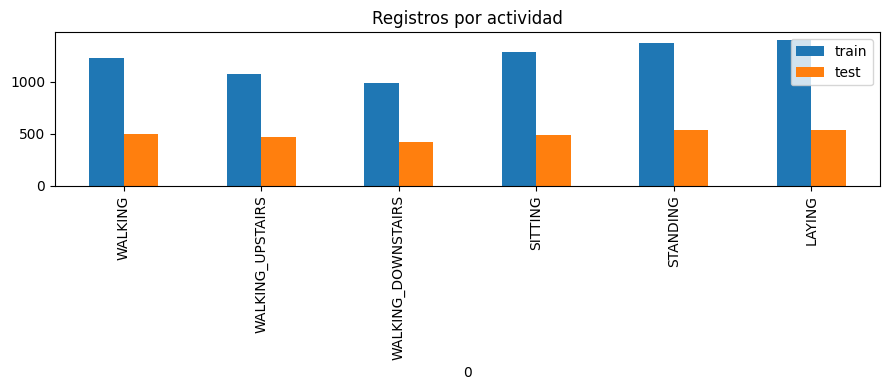

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

base = "../data"
rd = lambda f: pd.read_csv(f"{base}/{f}", sep=r"\s+", header=None)

X_train = rd("train/X_train.txt")
X_test = rd("test/X_test.txt")
y_train = pd.read_csv(f"{base}/train/y_train.txt", header=None)[0]
y_test = pd.read_csv(f"{base}/test/y_test.txt", header=None)[0]
labels = pd.read_csv(f"{base}/activity_labels.txt", sep=r"\s+", header=None, index_col=0)[1]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Nulos:", int(X_train.isna().sum().sum()) + int(X_test.isna().sum().sum()))

conteo = pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
})
conteo.index = conteo.index.map(labels)
print(conteo)

conteo.plot(kind="bar", figsize=(9, 4), title="Registros por actividad")
plt.tight_layout()
plt.show()

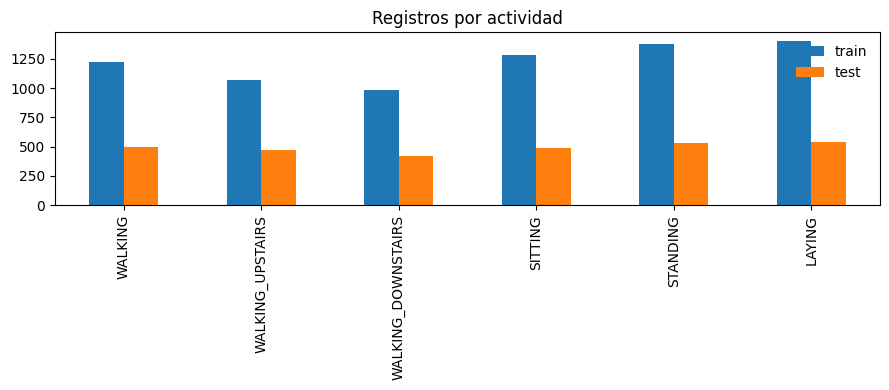

Duplicados en train: 0
Duplicados en test: 0
Valor mínimo: -1.0 | Valor máximo: 1.0


In [2]:
conteo.index.name = None
ax = conteo.plot(kind="bar", figsize=(9, 4), title="Registros por actividad")
ax.set_xlabel("")
ax.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

print("Duplicados en train:", int(X_train.duplicated().sum()))
print("Duplicados en test:", int(X_test.duplicated().sum()))
print("Valor mínimo:", round(X_train.min().min(), 3), "| Valor máximo:", round(X_train.max().max(), 3))

In [3]:
import numpy as np
from sklearn.decomposition import PCA

print("Rango en test -> min:", round(X_test.min().min(), 3), "| max:", round(X_test.max().max(), 3))

corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pares_altos = (upper > 0.95).sum().sum()
cols_redundantes = [c for c in upper.columns if (upper[c] > 0.95).any()]
print("Pares con correlación > 0.95:", int(pares_altos))
print("Variables con alguna correlación > 0.95:", len(cols_redundantes), "de", X_train.shape[1])

pca = PCA().fit(X_train)
acum = np.cumsum(pca.explained_variance_ratio_)
for k in [2, 10, 50, 100]:
    print(f"Varianza explicada con {k} componentes: {acum[k-1]:.3f}")
print("Componentes para 95%:", int(np.argmax(acum >= 0.95)) + 1)

Rango en test -> min: -1.0 | max: 1.0
Pares con correlación > 0.95: 2281
Variables con alguna correlación > 0.95: 308 de 561
Varianza explicada con 2 componentes: 0.675
Varianza explicada con 10 componentes: 0.805
Varianza explicada con 50 componentes: 0.931
Varianza explicada con 100 componentes: 0.973
Componentes para 95%: 67


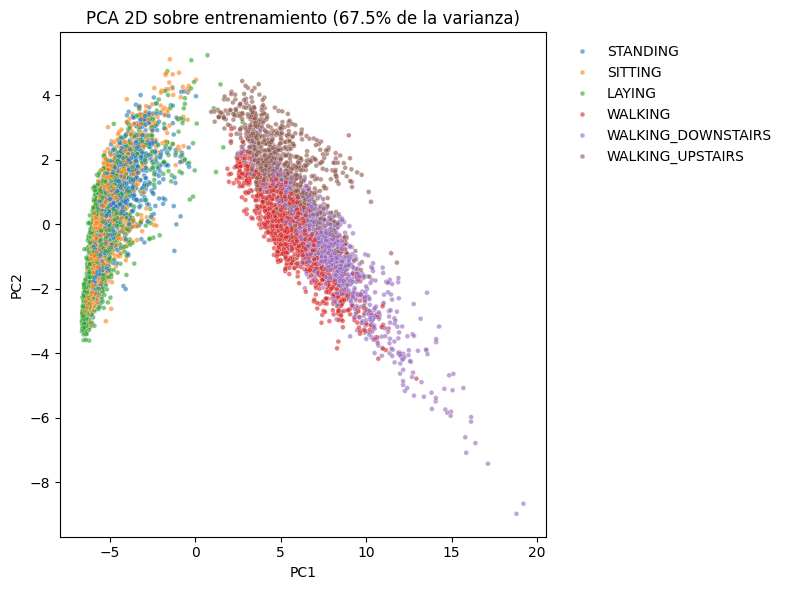

In [4]:
import seaborn as sns

pca2 = PCA(n_components=2).fit(X_train)
Z = pca2.transform(X_train)
df_pca = pd.DataFrame({"PC1": Z[:, 0], "PC2": Z[:, 1], "actividad": y_train.map(labels)})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="actividad", s=12, alpha=0.6, palette="tab10")
plt.title("PCA 2D sobre entrenamiento (67.5% de la varianza)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

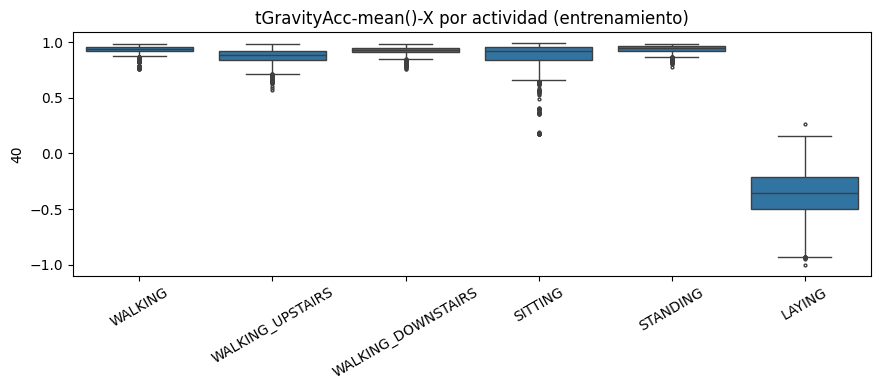

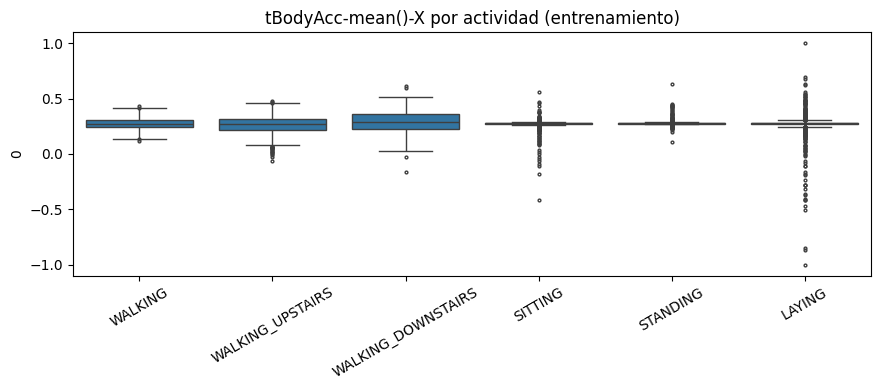

In [5]:
nombres = pd.read_csv(f"{base}/features.txt", sep=r"\s+", header=None)[1].tolist()
actividad = y_train.map(labels)

for var in ["tGravityAcc-mean()-X", "tBodyAcc-mean()-X"]:
    i = nombres.index(var)
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.boxplot(x=actividad, y=X_train[i], order=labels.tolist(), ax=ax, fliersize=2)
    ax.set_title(f"{var} por actividad (entrenamiento)")
    ax.set_xlabel("")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [6]:
[n for n in nombres if "Mag-mean" in n]

['tBodyAccMag-mean()',
 'tGravityAccMag-mean()',
 'tBodyAccJerkMag-mean()',
 'tBodyGyroMag-mean()',
 'tBodyGyroJerkMag-mean()',
 'fBodyAccMag-mean()',
 'fBodyAccMag-meanFreq()',
 'fBodyBodyAccJerkMag-mean()',
 'fBodyBodyAccJerkMag-meanFreq()',
 'fBodyBodyGyroMag-mean()',
 'fBodyBodyGyroMag-meanFreq()',
 'fBodyBodyGyroJerkMag-mean()',
 'fBodyBodyGyroJerkMag-meanFreq()']

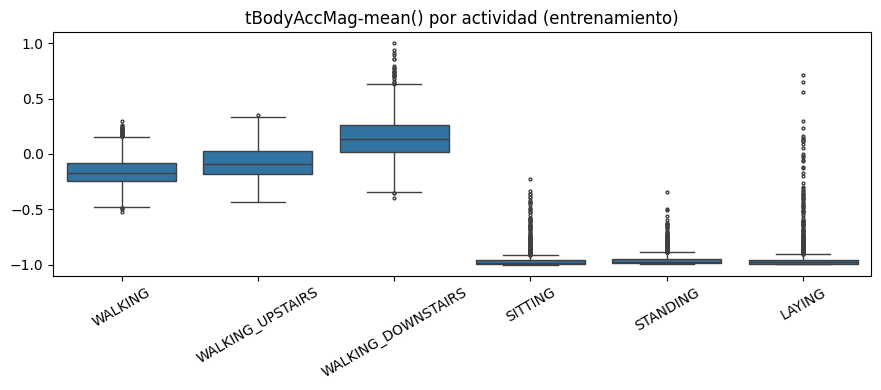

           mean    25%    50%    75%
0                                   
dinámica -0.043 -0.193 -0.078  0.089
estática -0.948 -0.991 -0.981 -0.955


In [7]:
var = "tBodyAccMag-mean()"
i = nombres.index(var)

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(x=actividad, y=X_train[i], order=labels.tolist(), ax=ax, fliersize=2)
ax.set_title(f"{var} por actividad (entrenamiento)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

grupo = actividad.map(lambda a: "dinámica" if a.startswith("WALKING") else "estática")
print(X_train[i].groupby(grupo).describe()[["mean", "25%", "50%", "75%"]].round(3))